<a href="https://colab.research.google.com/github/sofyakapanova/ML/blob/main/ai_vs_human_classification.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# AI vs Human Academic Writing — бинарная классификация

**Задача.** По лингвистическим метрикам (они описывают готовый текст) текста, «поведенческой телеметрии» (данные о поведении автора во время набора текста, они описывают процесс создания этого текста) и другим признакам определить, написан ли академический текст человеком (0) или с помощью ИИ (1) (обнаружение ИИ-ассистированных академических работ).

Датасет содержит 10 200 строк (каждая строка датасета — одна студенческая академическая работа) и 20 колонок: 18 признаков, идентификатор `Student_ID` и целевая переменная `Is_AI_Assisted`. Признаки делятся на три группы.

**Лингвистические характеристики текста (8):** `Word_Count` (длина), `Average_Sentence_Length` (средняя длина предложения), `Grammar_Errors` (число грамматических ошибок), `Vocabulary_Richness` (богатство словаря), `Passive_Voice_Ratio` (доля пассивного залога), `Reading_Level` (индекс читаемости), `Punctuation_Density` (плотность пунктуации), `Sentence_Complexity` (сложность предложений).

**Поведенческая телеметрия (5):** `Editing_Time` (суммарное время редактирования), `Revision_Count` (число правок), `Typing_Speed` (скорость печати), `Plagiarism_Score` (доля заимствованного текста), `Citation_Count` (число цитирований).

**Категориальные и контекстные признаки (5):** `Submission_Type` (тип работы: эссе / лабораторный отчёт / исследовательская статья), `Academic_Level` (академический уровень: бакалавриат / магистратура), `Primary_Language` (родной язык: английский родной / не родной), `Font_Family` (шрифт), `Submission_Hour` (час сдачи работы).

Идентификатор `Student_ID` уникален для каждой записи и в модель не идёт.

Целевая переменная — `Is_AI_Assisted`: 0 — текст написан человеком, 1 — написан с помощью ИИ. Это задача **бинарной классификации**.


## 1. Чтение данных

Загружаем датасет напрямую с Kaggle через `kagglehub`.

Смотрим размер таблицы (`N` — число строк, `D` — число колонок) и первые пять строк, чтобы убедиться, что данные прочитались корректно.

In [73]:
import kagglehub
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option('display.max_columns', 50)

path = kagglehub.dataset_download(
    "razanihababdellatif/ai-vs-human-academic-writing-dataset")
print("Path to dataset files:", path)
print("Файлы:", os.listdir(path))

csv_path = os.path.join(path, "ai_writing_detection_dataset.csv")
df = pd.read_csv(csv_path)

print(f'\nЗагружено: N = {df.shape[0]}, D = {df.shape[1]}')
df.head()

Using Colab cache for faster access to the 'ai-vs-human-academic-writing-dataset' dataset.
Path to dataset files: /kaggle/input/ai-vs-human-academic-writing-dataset
Файлы: ['ai_writing_detection_dataset.csv']

Загружено: N = 10200, D = 20


,Student_ID,Submission_Type,Academic_Level,Primary_Language,Word_Count,Average_Sentence_Length,Grammar_Errors,Vocabulary_Richness,Passive_Voice_Ratio,Reading_Level,Editing_Time,Revision_Count,Typing_Speed,Plagiarism_Score,Citation_Count,Punctuation_Density,Sentence_Complexity,Font_Family,Submission_Hour,Is_AI_Assisted
0,16959e76,Lab_Report,Postgraduate,Native,1552,16.90,8,0.62,0.11,11.85,129.05,16.0,24.70,3.02,0.0,0.08,2.01,Arial,18,0
1,0a304e7f,Research_Paper,Undergraduate,Native,950,16.71,5,0.47,0.31,10.34,236.60,23.0,38.84,1.71,15.0,0.07,1.72,Helvetica,15,0
2,6e629f9f,Essay,Undergraduate,Non_Native,1103,22.10,1,0.76,0.38,14.35,4.72,4.0,0.00,0.41,0.0,0.08,2.35,Arial,17,1
3,16334d32,Essay,Postgraduate,Native,1189,20.00,7,0.61,0.26,10.93,NaN,24.0,41.92,3.06,5.0,0.05,1.68,Times New Roman,5,0
4,54d8e254,Essay,Undergraduate,Native,1035,22.67,2,0.80,0.33,15.30,16.82,2.0,0.00,2.78,1.0,0.09,2.90,Helvetica,8,1


## 2. Разбиение на train/test

Разбиваем данные на обучающую (80%) и тестовую (20%) выборки **до любой обработки** — иначе метрики на тесте будут завышены.

Разбиение **стратифицированное** (`stratify=y`): доли классов в train и test сохраняются такими же, как в исходном датасете (~85.5% / 14.5%). Без стратификации при сильном дисбалансе может случиться, что в тест попадёт непропорционально много или мало объектов меньшего класса — метрики станут нестабильными.

Перед разбиением **удаляем дубликаты по Student_ID** (~2% строк). Если один и тот же объект попадёт и в train, и в test, модель «увидит» тестовый пример при обучении — это утечка данных, завышающая качество.

`Student_ID` исключаем из признаков: это уникальный идентификатор, он не несёт информации о классе.

In [74]:
from sklearn.model_selection import train_test_split

TARGET = 'Is_AI_Assisted'
ID_COLS = ['Student_ID']

# убираем дубликаты по уникальному Student_ID (устойчиво к NaN в телеметрии)
print('Строк до удаления дубликатов:', len(df))
df = df.drop_duplicates(subset=['Student_ID'], keep='first').reset_index(drop=True)
print('Строк после удаления дубликатов:', len(df))

# проверка, что дубликатов не осталось
print('Осталось дубликатов по Student_ID:', df.duplicated(subset=['Student_ID']).sum())
print('Осталось полных дубликатов (с учётом NaN):', df.duplicated().sum())

X = df.drop(columns=[TARGET] + ID_COLS)
y = df[TARGET]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=42)

print(f'\nX_train: {X_train.shape} | X_test: {X_test.shape}')
print('\nДоли классов в train:')
display(y_train.value_counts(normalize=True).round(4).to_frame('доля'))
print('Доли классов в test:')
display(y_test.value_counts(normalize=True).round(4).to_frame('доля'))

Строк до удаления дубликатов: 10200
Строк после удаления дубликатов: 10000
Осталось дубликатов по Student_ID: 0
Осталось полных дубликатов (с учётом NaN): 0

X_train: (8000, 18) | X_test: (2000, 18)

Доли классов в train:


,доля
Is_AI_Assisted,
0,0.8552
1,0.1448


Доли классов в test:


,доля
Is_AI_Assisted,
0,0.855
1,0.145


## 3. Визуализация данных и основные характеристики

1. Разделяем колонки на числовые и категориальные — от этого зависит стратегия обработки.
2. Считаем описательные статистики: среднее, стандартное отклонение, квантили, минимум/максимум. Это даёт представление о масштабах и разбросе.
3. Строим корреляционную матрицу — ищем сильно коррелирующие признаки и связи с целевой переменной.
4. Смотрим распределение классов и наличие дисбаланса.
5. Строим боксплоты ключевых признаков **отдельно для каждого класса** — это самый важный график: он показывает, какие признаки действительно различают человек/ИИ и в какую сторону. Если медианы или разбросы заметно смещены — признак информативен для классификатора.

In [75]:
num_cols = X_train.select_dtypes(include=np.number).columns.tolist()
cat_cols = X_train.select_dtypes(include='object').columns.tolist()

print(f'Числовых признаков: {len(num_cols)}')
print(num_cols)
print(f'\nКатегориальных признаков: {len(cat_cols)}')
print(cat_cols)

print('\nОсновные характеристики числовых признаков:')
display(X_train[num_cols].describe().T.round(2))

Числовых признаков: 14
['Word_Count', 'Average_Sentence_Length', 'Grammar_Errors', 'Vocabulary_Richness', 'Passive_Voice_Ratio', 'Reading_Level', 'Editing_Time', 'Revision_Count', 'Typing_Speed', 'Plagiarism_Score', 'Citation_Count', 'Punctuation_Density', 'Sentence_Complexity', 'Submission_Hour']

Категориальных признаков: 4
['Submission_Type', 'Academic_Level', 'Primary_Language', 'Font_Family']

Основные характеристики числовых признаков:


,count,mean,std,min,25%,50%,75%,max
Word_Count,8000.0,1199.11,394.37,300.00,923.75,1194.00,1469.25,2517.00
Average_Sentence_Length,8000.0,16.95,4.62,5.00,13.67,17.09,20.62,33.62
Grammar_Errors,8000.0,7.32,5.07,0.00,5.00,7.00,9.00,78.00
Vocabulary_Richness,8000.0,0.62,0.10,0.29,0.55,0.62,0.70,0.90
Passive_Voice_Ratio,8000.0,0.20,0.10,0.00,0.13,0.20,0.27,0.52
Reading_Level,8000.0,11.49,2.53,5.00,9.73,11.57,13.43,20.00
Editing_Time,7301.0,162.11,110.50,1.00,112.40,168.08,214.17,1493.40
Revision_Count,6791.0,21.57,9.38,0.00,19.00,24.00,28.00,45.00
Typing_Speed,7218.0,165.62,356.55,0.00,34.89,46.50,59.48,1200.00
Plagiarism_Score,7369.0,7.10,7.60,0.00,1.80,4.62,9.71,72.33


**Интерпретация основных характеристик.**

**Типы признаков.** 14 числовых и 4 категориальных. В числовых — 8 лингвистических, 5 телеметрических и `Submission_Hour`. Категориальные (`Submission_Type`, `Academic_Level`, `Primary_Language`, `Font_Family`) имеют 2–7 уровней. `Student_ID` и `Is_AI_Assisted` в список не вошли: идентификатор исключён как не несущий информации, целевая переменная обрабатывается отдельно.

**Пропуски.** Пропуски сосредоточены ровно в телеметрии:

- `Revision_Count` — 6791 (пропущено 15.1%),
- `Typing_Speed` — 7218 (9.8%),
- `Citation_Count` — 7221 (9.7%),
- `Editing_Time` — 7301 (8.7%),
- `Plagiarism_Score` — 7369 (7.9%).

В лингвистических и категориальных признаках пропусков нет.

**Масштабы.** Признаки измеряются в разных единицах: `Word_Count` — сотни и тысячи (300–2517), доли `Vocabulary_Richness`, `Passive_Voice_Ratio`, `Punctuation_Density` лежат в [0, 1], `Reading_Level` — баллы 5–20, `Typing_Speed` — символы в минуту (0–1200), `Submission_Hour` — часы 0–23. Без `StandardScaler` kNN будет сравнивать несравнимое: разброс `Word_Count` в сотни полностью подавит разброс `Vocabulary_Richness` в 0.1. Нормализация обязательна.

**Разброс и форма распределений.** У большинства признаков `std` умеренный относительно `mean`. Исключения — телеметрия:

- `Typing_Speed`: `mean = 165.6`, `std = 356.6`, `max = 1200` при медиане 46.5. Среднее сильно «уехало» вправо из-за выбросов, распределение скошено вправо. Медиана здесь честнее среднего.
- `Editing_Time`: `mean = 162`, `std = 110`, `max = 1493` при медиане 168 — тоже длинный правый хвост.
- `Plagiarism_Score`: медиана 4.6, `max = 72.3` — отдельные тексты с очень высокой долей заимствований.
- `Grammar_Errors`: медиана 7, `max = 78` — отдельные объекты с аномально большим числом ошибок (11-кратное превышение медианы).

Значения не разбросаны широко, а лежат в узком диапазоне вокруг центра — `Vocabulary_Richness` (0.29–0.90, медиана 0.62), `Passive_Voice_Ratio` (0–0.52, медиана 0.20), `Punctuation_Density` (0–0.13, медиана 0.05). `Submission_Hour` распределён примерно равномерно по суткам (медиана 12, квартили 6–18), что логично для случайного времени сдачи.

**Что это значит для дальнейшей обработки.**

1. **Клиппирование по IQR необходимо.** У `Typing_Speed`, `Editing_Time`, `Revision_Count` и `Plagiarism_Score` есть длинные правые хвосты. Если их не подрезать, выбросы исказят евклидовы расстояния в kNN (аномальный объект окажется «бесконечно далеко» от остальных) и увеличат стандартное отклонение, из-за чего `StandardScaler` сожмёт нормальные значения в узкий диапазон около нуля.

2. **Заполнять пропуски нужно медианой, а не средним.** У скошенных признаков среднее смещено в сторону выбросов и плохо описывает «типичное» значение. Наглядный пример — `Typing_Speed`: `mean = 165.6` при медиане 46.5, то есть среднее втрое больше типичного значения. Медиана устойчива к выбросам и даёт более честную оценку центра.

3. **Стандартизация обязательна.** Признаки измеряются в разных единицах и различаются по масштабу. Без приведения к единому масштабу kNN будет сравнивать несравнимое.

4. **Наиболее информативными, по предварительной гипотезе, будут** `Typing_Speed`, `Editing_Time`, `Revision_Count` и `Grammar_Errors`: у них наибольший разброс, и по смыслу они должны сильнее всего различать человека и ИИ. Проверим это боксплотами по классам (ниже) и важностью признаков RandomForest (пункт 10).

**Корреляционная матрица.** Это таблица, которая показывает, насколько каждый признак связан с каждым другим.

1. Если два признака сильно коррелируют между собой (коэффициент корреляции по модулю больше 0.7), они несут почти одну и ту же информацию. Один из них можно убрать — модель не потеряет в качестве, но станет проще и быстрее.

2. **Какие признаки сильнее связаны с целевой переменной?** Смотрим строку/столбец `Is_AI_Assisted` в матрице: чем выше корреляция признака с целевой переменной, тем полезнее этот признак для предсказания класса.

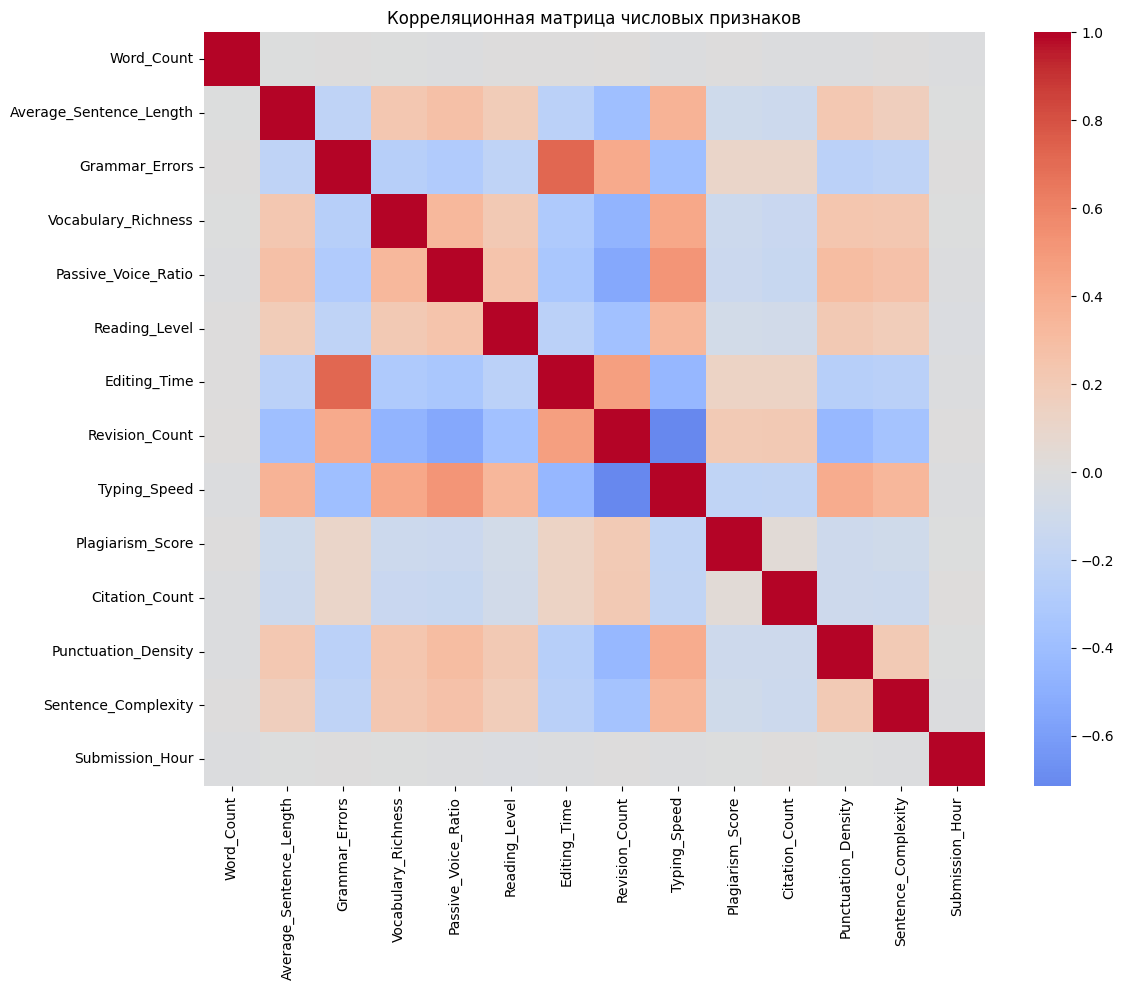

In [76]:
plt.figure(figsize=(12, 10))
sns.heatmap(X_train[num_cols].corr(), annot=False, cmap='coolwarm', center=0)
plt.title('Корреляционная матрица числовых признаков')
plt.tight_layout()
plt.show()

**Интерпретация корреляционной матрицы.**

Сильных корреляций между признаками нет, поэтому **ни один признак не исключаем** — все 14 числовых остаются в модели.

**Заметные связи:**

- `Grammar_Errors` ↔ `Editing_Time` (**+0.50**) — умеренная положительная связь: больше времени на редактирование сочетается с большим числом грамматических ошибок. Логично: человек правит текст итеративно, и в процессе появляются ошибки.
- `Revision_Count` ↔ `Typing_Speed` (**−0.32**) — слабая отрицательная связь: чем выше скорость печати, тем меньше правок. Согласуется с гипотезой: быстрый набор часто означает вставку готового текста (ИИ), а не итеративное редактирование.
- `Editing_Time` ↔ `Average_Sentence_Length` (**−0.30**) — слабая отрицательная связь: длинные предложения сочетаются с **меньшим** временем редактирования. Косвенный признак ИИ-текста: ИИ пишет длинными предложениями, но редактируется мало.
- `Typing_Speed` ↔ `Grammar_Errors` (**−0.26**) — слабая отрицательная связь: быстрая печать сочетается с **меньшим** числом ошибок. Согласуется с гипотезой: ИИ печатает быстро и почти без ошибок.
- `Typing_Speed` ↔ `Passive_Voice_Ratio` (**+0.25**) — слабая положительная связь: быстрая печать сочетается с более высокой долей пассивного залога. Тоже согласуется с гипотезой: ИИ чаще использует пассив.

**Слабо связанные признаки:** `Word_Count`, `Plagiarism_Score`, `Citation_Count`, `Submission_Hour` почти не коррелируют с остальными (`|r| < 0.1`). Это хорошо: они дают модели независимый сигнал, не дублируя другие признаки.

**Общий паттерн.** Корреляции `Typing_Speed` с другими признаками распадаются на две группы:

- **отрицательные** с `Revision_Count` (−0.32) и `Grammar_Errors` (−0.26) — быстрая печать сочетается с малым числом правок и ошибок;
- **положительные** с `Passive_Voice_Ratio` (+0.25) и `Reading_Level` (+0.16) — быстрая печать сочетается с более высоким пассивным залогом и читательским уровнем.

Оба направления согласуются с гипотезой, что `Typing_Speed` — маркер ИИ-текста: ИИ печатается быстро, почти не правится, содержит мало ошибок, но использует пассивный залог и сложную лексику.


Добавим `Is_AI_Assisted` в матрицу отдельной ячейкой, чтобы увидеть, у каких признаков корреляция с классом наибольшая.

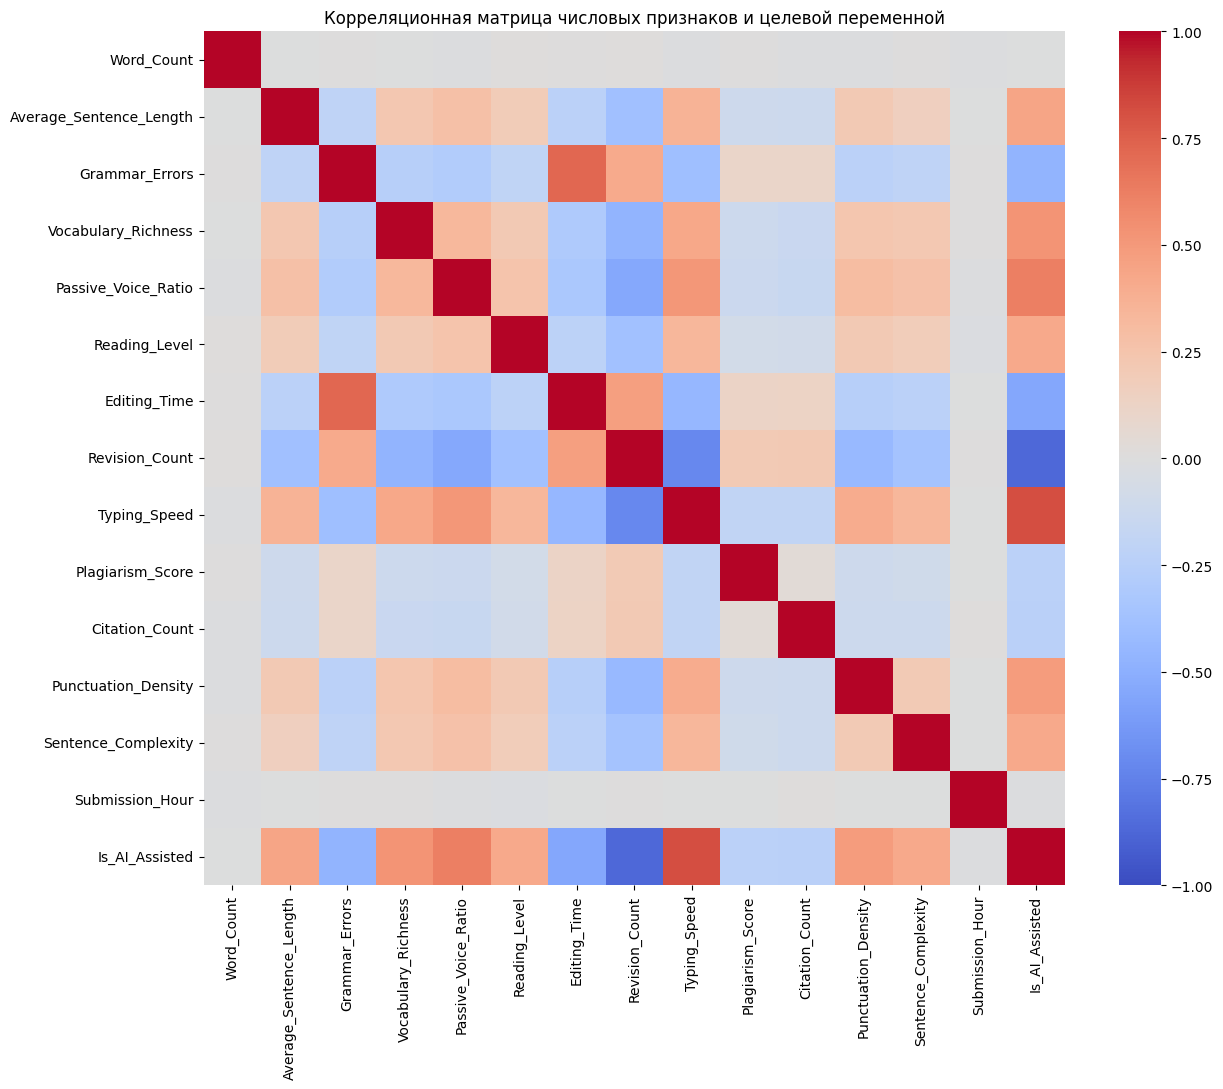

In [77]:
corr_data = X_train[num_cols].copy()
corr_data['Is_AI_Assisted'] = y_train.values

plt.figure(figsize=(13, 11))
sns.heatmap(corr_data.corr(), annot=False, cmap='coolwarm', center=0, vmin=-1, vmax=1)
plt.title('Корреляционная матрица числовых признаков и целевой переменной')
plt.tight_layout()
plt.show()

**Связь с целевой переменной `Is_AI_Assisted`.** По нижней строке и правому столбцу видно, какие признаки сильнее всего различают человека и ИИ. Знак корреляции показывает направление: положительная — чем больше признак, тем чаще объект относится к классу 1 (ИИ); отрицательная — тем реже.

**Очень сильная отрицательная связь** (у ИИ значения существенно ниже):
- **`Revision_Count`** (**−0.83**) — самая сильная связь. У ИИ в 4.5 раза меньше правок (медиана 5.5 против 25). ИИ-текст вставляется готовым, человек переписывает итеративно.
- **`Editing_Time`** (**−0.72**) — у ИИ в 18 раз меньше время редактирования (медиана 9.75 против 181).
- **`Grammar_Errors`** (**−0.66**) — у ИИ в 8 раз меньше грамматических ошибок (медиана 1 против 8).

**Умеренная отрицательная связь:**
- **`Plagiarism_Score`** (**−0.26**) — у ИИ ниже доля заимствований (медиана 2.8 против 7.3).
- **`Citation_Count`** (**−0.24**) — у ИИ меньше цитирований (медиана 4 против 10).

**Сильная положительная связь** (у ИИ значения выше):
- **`Passive_Voice_Ratio`** (**+0.62**) — у ИИ почти вдвое выше доля пассивного залога (0.35 против 0.18).
- **`Vocabulary_Richness`** (**+0.53**) — у ИИ богаче словарь (0.75 против 0.60).
- **`Punctuation_Density`** (**+0.49**) — у ИИ плотнее пунктуация (0.08 против 0.05).
- **`Average_Sentence_Length`** (**+0.44**) — у ИИ длиннее предложения (21.9 против 16.1).
- **`Sentence_Complexity`** (**+0.42**) — у ИИ сложнее предложения (2.5 против 1.8).
- **`Reading_Level`** (**+0.42**) — у ИИ выше читательский уровень (14.1 против 11.1).
- **`Typing_Speed`** (**+0.38**) — у ИИ выше скорость печати (96.4 против 45).

**Почти нулевая связь:** `Word_Count` (**−0.004**) и `Submission_Hour` (**−0.010**) — у ИИ и человека распределения почти совпадают, признаки не различают классы.

**Что это значит для модели.**

1. **Связи с классом сильные.** Три признака — `Revision_Count` (−0.83), `Editing_Time` (−0.72) и `Grammar_Errors` (−0.66) — почти полностью разделяют классы. У ИИ медианы в 4–18 раз ниже. Этого достаточно, чтобы модель почти безошибочно определяла класс — что и объясняет идеальные метрики в пунктах 9–10.

2. **`Passive_Voice_Ratio` (+0.62) и `Vocabulary_Richness` (+0.53) — тоже сильные признаки,** но с положительным знаком. Вместе с телеметрией они дают модели несколько независимых «осей» разделения классов.

3. **`Word_Count` и `Submission_Hour` — единственные признаки с почти нулевой связью.** Это подтвердилось в feature importance (п.10): их важность ~0.0005 и ~0.0003. `Font_Family` тоже в хвосте, но в числовую матрицу не попал (категориальный).

4. **Признаки с |r| > 0.4 (всего восемь: `Revision_Count`, `Editing_Time`, `Grammar_Errors`, `Passive_Voice_Ratio`, `Vocabulary_Richness`, `Punctuation_Density`, `Average_Sentence_Length`, `Sentence_Complexity`, `Reading_Level`) — основные кандидаты на высокую важность.** Feature importance RandomForest (п.10) это подтвердила: топ-6 — ровно из этой группы.

5. **Направления согласуются с гипотезами.** ИИ-тексты: мало правок, мало времени на редактирование, мало грамматических ошибок, но при этом богаче словарь, длиннее и сложнее предложения, чаще пассивный залог, плотнее пунктуация.

**Распределение классов.**

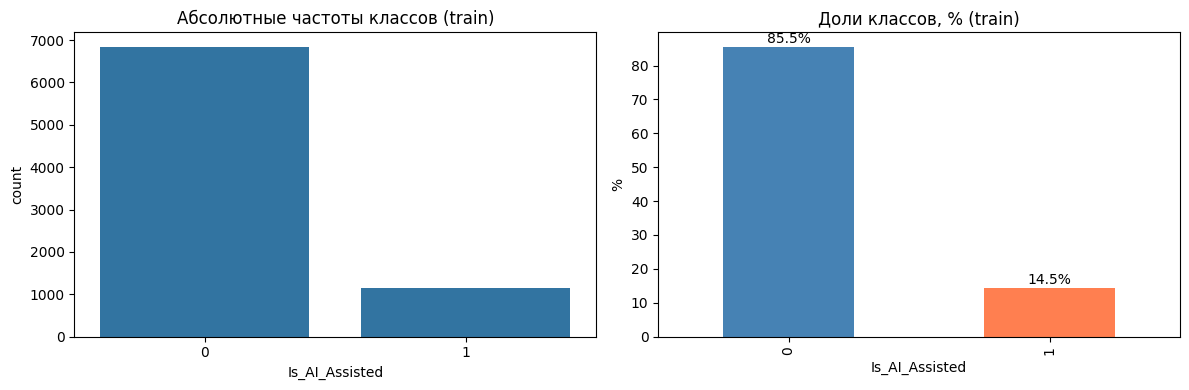

In [78]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x=y_train, ax=ax[0])
ax[0].set_title('Абсолютные частоты классов (train)')
ax[0].set_xlabel('Is_AI_Assisted')

(y_train.value_counts(normalize=True) * 100).plot(
    kind='bar', ax=ax[1], color=['steelblue', 'coral'])
ax[1].set_title('Доли классов, % (train)')
ax[1].set_ylabel('%')
for i, v in enumerate((y_train.value_counts(normalize=True) * 100).values):
    ax[1].text(i, v + 1, f'{v:.1f}%', ha='center')
plt.tight_layout()
plt.show()

**Интерпретация распределения классов.**

На train-выборке 6840 объектов класса 0 (человек) и 1160 объектов класса 1 (ИИ) — это 85.5% и 14.5% соответственно. Дисбаланс подтверждён.

**Последствия для модели.**

1. **Accuracy обманчива.** Модель, которая всегда предсказывает класс 0, даст accuracy = 0.855, но не найдёт ни одного ИИ-текста. Такая метрика создаёт иллюзию хорошего качества, поэтому **accuracy не может быть основной метрикой**.

2. **"Голосование" kNN смещается в сторону мажоритарного класса.** Класс 0 (человек) составляет 85.5% обучающей выборки, класс 1 (ИИ) — только 14.5%. Поэтому среди k ближайших соседей любого объекта статистически преобладают объекты класса 0. Если k = 5, то в среднем 4 из 5 соседей окажутся классом 0 — и kNN выберет класс 0, даже если сам объект на самом деле относится к классу 1. В результате модель почти всегда предсказывает «человек» и плохо находит ИИ-тексты. Редкий класс плохо находится.

3. **Нужны метрики, устойчивые к дисбалансу.** Accuracy здесь не подходит: модель «всегда человек» даёт 0.855, но не находит ни одного ИИ-текста. Поэтому используем:

- **Recall по классу 1** — доля реальных ИИ-текстов, которые модель нашла. Это главная метрика: пропустить ИИ-работу хуже, чем ошибочно заподозрить человека, потому что пропущенная работа уходит в зачёт как «честная».
- **F1 по классу 1** — гармоническое среднее precision и recall по классу ИИ. Одна цифра, которая балансирует обе стороны и позволяет сравнивать модели.
- **Balanced accuracy** — среднее recall по классам. В отличие от accuracy, не вознаграждает за игнорирование редкого класса: у модели «всегда 0» balanced accuracy = 0.5, а не 0.855.
- **ROC-AUC** — качество ранжирования по вероятности. Не зависит от порога и от дисбаланса: случайная модель даёт 0.5, идеальная — 1.0. Если AUC высокий, но recall при пороге 0.5 низкий, можно снизить порог и поймать больше ИИ.

4. **В моделях используем `class_weight='balanced'`** (LogisticRegression, RandomForest). Этот параметр задаёт веса классов обратно пропорционально их частотам: ошибка на объекте редкого класса «стоит» дороже, чем на объекте частого. В результате модель сильнее штрафуется за пропуск ИИ-текстов и начинает их находить чаще (ценой некоторого роста ложных срабатываний). Для kNN этот параметр недоступен, поэтому альтернатива — **SMOTE**: он генерирует синтетические объекты редкого класса и применяется только к train внутри `imblearn.Pipeline`, чтобы не было утечки в тест.

## 4. Выбросы

В датасете есть выбросы (аномально долгое редактирование, очень высокое число грамматических ошибок). Всего хотя бы один выброс есть у 20.69% строк. Удалять их нельзя — потеряем пятую часть данных и исказим распределение классов.

**Что делаем:** клиппируем (всё, что выходит за допустимые границы, не удаляется, а заменяется на саму границу) значения по правилу IQR: всё, что ниже `Q1 − 1.5·IQR` или выше `Q3 + 1.5·IQR`, заменяем на соответствующую границу. Это сохраняет объекты, но убирает чрезмерное влияние выбросов на расстояния и масштаб.

**Важно:**  границы `Q1`, `Q3` и `IQR` вычисляем на **train** и применяем готовые числа к **test** — иначе информация из теста «протечёт» в обучение. Для kNN клиппирование особенно критично: евклидово расстояние чувствительно к выбросам — один объект с аномально большим значением окажется «бесконечно далеко» от всех и не будет ничьим соседом.

In [79]:
# Доля строк хотя бы с одним выбросом (по любому числовому признаку)
mask_out = pd.Series(False, index=X_train.index)
for c in num_cols:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3 - q1
    mask_out |= (X_train[c] < q1 - 1.5*iqr) | (X_train[c] > q3 + 1.5*iqr)

print(f'Строк хотя бы с одним выбросом: {mask_out.sum()} '
      f'({mask_out.mean()*100:.2f}%)')

Строк хотя бы с одним выбросом: 1655 (20.69%)


In [80]:
# Подсчёт выбросов по IQR до клиппирования
outlier_report = []
for c in num_cols:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3 - q1
    n_out = ((X_train[c] < q1 - 1.5*iqr) | (X_train[c] > q3 + 1.5*iqr)).sum()
    outlier_report.append((c, n_out, n_out / len(X_train) * 100))

outlier_df = pd.DataFrame(outlier_report,
                          columns=['feature', 'n_outliers', '%']).sort_values(
                          'n_outliers', ascending=False)
display(outlier_df.round(2))

,feature,n_outliers,%
7,Revision_Count,998,12.48
8,Typing_Speed,768,9.60
9,Plagiarism_Score,409,5.11
2,Grammar_Errors,101,1.26
6,Editing_Time,43,0.54
0,Word_Count,15,0.19
12,Sentence_Complexity,8,0.10
5,Reading_Level,7,0.09
3,Vocabulary_Richness,5,0.06
4,Passive_Voice_Ratio,5,0.06


**Боксплоты до и после клиппирования.** Строим боксплоты для нескольких ключевых признаков в двух вариантах — до и после клиппирования. Сравниваем: экстремальные значения («усы» и точки-выбросы) должны подрезаться, а основная часть распределения — остаться на месте.

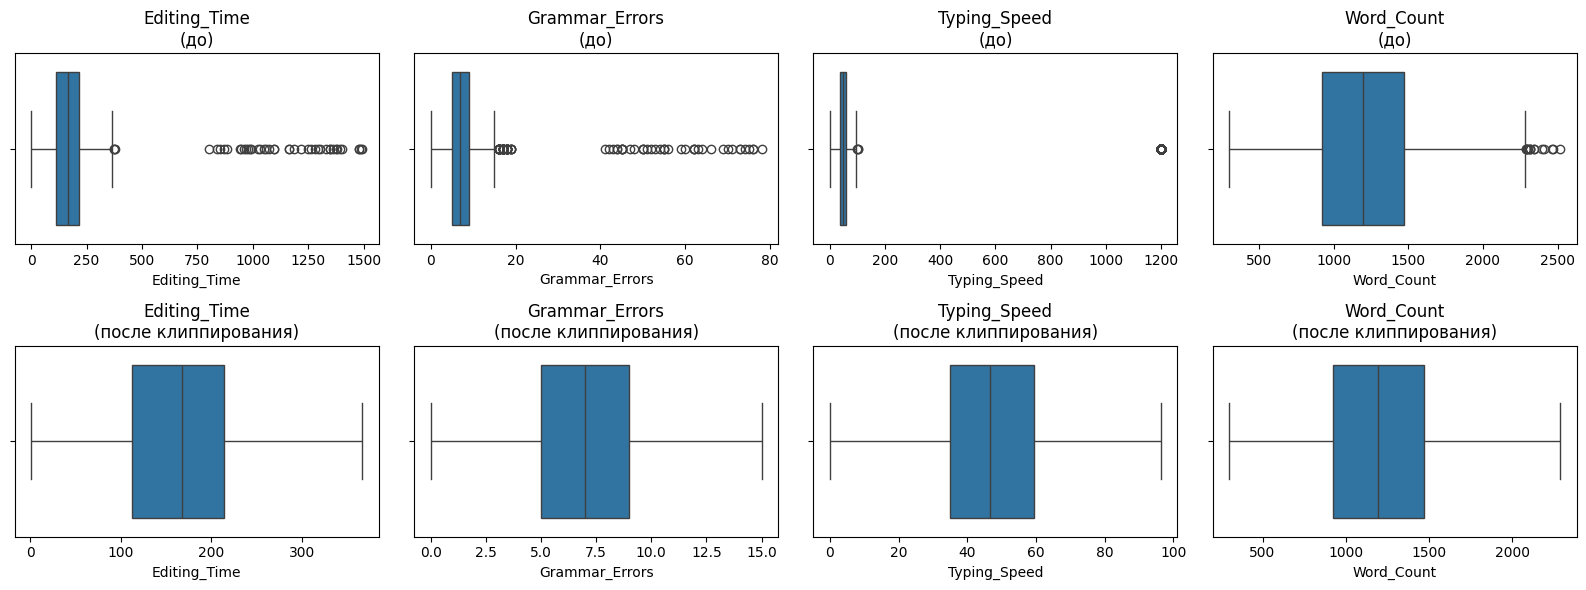

Клиппирование по IQR выполнено (границы из train).
Выбросов в train после клиппирования: 0


In [81]:
def clip_iqr(s):
    q1, q3 = s.quantile([.25, .75])
    iqr = q3 - q1
    return s.clip(q1 - 1.5*iqr, q3 + 1.5*iqr)

def clip_iqr_train_test(train, test, cols):
    """Клиппирование по IQR: границы считаем на train, применяем к train и test."""
    train = train.copy()
    test = test.copy()
    for c in cols:
        q1, q3 = train[c].quantile([.25, .75])
        iqr = q3 - q1
        lo, hi = q1 - 1.5*iqr, q3 + 1.5*iqr
        train[c] = train[c].clip(lo, hi)
        test[c]  = test[c].clip(lo, hi)
    return train, test

show_cols = ['Editing_Time', 'Grammar_Errors', 'Typing_Speed', 'Word_Count']
show_cols = [c for c in show_cols if c in X_train.columns]

fig, axes = plt.subplots(2, len(show_cols), figsize=(16, 6))
for j, c in enumerate(show_cols):
    sns.boxplot(x=X_train[c], ax=axes[0, j])
    axes[0, j].set_title(f'{c}\n(до)')
    sns.boxplot(x=clip_iqr(X_train[c]), ax=axes[1, j])
    axes[1, j].set_title(f'{c}\n(после клиппирования)')
plt.tight_layout()
plt.show()

# Применяем клиппирование: границы из train, применяем к train и test
X_train, X_test = clip_iqr_train_test(X_train, X_test, num_cols)
print('Клиппирование по IQR выполнено (границы из train).')

# Проверка, что в train выбросов не осталось
n_out = 0
for c in num_cols:
    q1, q3 = X_train[c].quantile([.25, .75])
    iqr = q3 - q1
    n_out += ((X_train[c] < q1 - 1.5*iqr) | (X_train[c] > q3 + 1.5*iqr)).sum()
print(f'Выбросов в train после клиппирования: {n_out}')

**Интерпретация боксплотов до и после клиппирования.**

На графиках — четыре признака с наибольшим числом выбросов: `Editing_Time`, `Grammar_Errors`, `Typing_Speed` и `Word_Count`.

**До клиппирования.** У всех четырёх признаков видны длинные «усы» и россыпь точек-выбросов справа:

**После клиппирования.** У всех четырёх признаков «усы» подрезаны до границ `Q1 − 1.5·IQR` и `Q3 + 1.5·IQR`, точки-выбросы исчезли. "Ящики" и медианы **не сдвинулись** — это важно: клиппирование затронуло только хвосты, а основное распределение осталось прежним. Значит, границы IQR подобраны корректно и не «съели» нормальные значения.

**Что это даёт для модели.**

1. **Для kNN.** Евклидово расстояние больше не искажается объектами с аномальными значениями.

2. **Для `StandardScaler`.** Стандартное отклонение больше не увеличивается выбросами.


## 5. Пропущенные значения

Пропуски сосредоточены в пяти телеметрических признаках: Revision_Count (15.11%), Typing_Speed (9.78%), Citation_Count (9.74%), Editing_Time (8.74%), Plagiarism_Score (7.89%). В лингвистических и категориальных признаках пропусков нет.

Удалять строки с пропусками нельзя: потеряется до 15% данных, а среди них могут оказаться объекты редкого класса. Модели не работают с `NaN`, поэтому пропуски нужно заполнить.

**Что делаем:** заполняем пропуски внутри `Pipeline`, чтобы медиана и мода вычислялись **только на train** — иначе информация из теста «протечёт» в обучение.

- для числовых признаков используем **медиану** — она устойчива к выбросам, в отличие от среднего;
- для категориальных признаков используем **моду** — самое частое значение.

Технически это реализуется в `ColumnTransformer` ниже (пункт 6–7): `SimpleImputer(strategy='median')` для числовых колонок и `SimpleImputer(strategy='most_frequent')` для категориальных.

In [82]:
miss_train = (X_train.isna().mean() * 100).sort_values(ascending=False)
print('Пропуски в train (%):')
display(miss_train[miss_train > 0].round(2).to_frame('missing_%'))

miss_test = (X_test.isna().mean() * 100).sort_values(ascending=False)
print('\nПропуски в test (%):')
display(miss_test[miss_test > 0].round(2).to_frame('missing_%'))

Пропуски в train (%):


,missing_%
Revision_Count,15.11
Typing_Speed,9.78
Citation_Count,9.74
Editing_Time,8.74
Plagiarism_Score,7.89



Пропуски в test (%):


,missing_%
Revision_Count,13.80
Typing_Speed,10.10
Citation_Count,9.65
Plagiarism_Score,8.45
Editing_Time,8.40


## 6–7. Категориальные признаки и нормализация

**Категориальные признаки:** `Submission_Type`, `Academic_Level`, `Primary_Language`, `Font_Family`. Модели работают только с числовыми признаками, поэтому кодируем их через **One-Hot** — это способ превратить категориальный признак в числа, понятные модели. Как работает: для каждого уникального уровня признака создаётся отдельный бинарный столбец. Если объект относится к этому уровню — в столбце 1, иначе 0. One-Hot подходит для номинальных признаков с небольшим числом уровней (у нас 3–7 значений на признак)

**Нормализация нужна**, потому что признаки измеряются в разных шкалах: `Word_Count` — сотни, `Vocabulary_Richness` лежит в диапазоне [0, 1], `Editing_Time` — минуты и часы. kNN основан на евклидовом расстоянии: без масштабирования признак с большим разбросом будет доминировать в расстоянии, и модель фактически проигнорирует остальные признаки. `StandardScaler` вычитает из каждого значения среднее и делит на стандартное отклонение — после этого у каждого признака среднее ≈ 0, а стандартное отклонение ≈ 1, и все признаки вносят сопоставимый вклад в расстояние.

**Что делаем:** собираем `ColumnTransformer`, который для числовых колонок выполняет заполнение пропусков медианой и стандартизацию (`StandardScaler`), а для категориальных — заполнение пропусков модой и One-Hot-кодирование (`OneHotEncoder`). Трансформер обучается (`fit`) только на train, поэтому утечки данных из теста не будет.

In [83]:
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

preprocess = ColumnTransformer([
    ('num', Pipeline([
        ('imp', SimpleImputer(strategy='median')),
        ('sc', StandardScaler())
    ]), num_cols),
    ('cat', Pipeline([
        ('imp', SimpleImputer(strategy='most_frequent')),
        ('oh', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print('ColumnTransformer готов:')
print(preprocess)

ColumnTransformer готов:
ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='median')),
                                                 ('sc', StandardScaler())]),
                                 ['Word_Count', 'Average_Sentence_Length',
                                  'Grammar_Errors', 'Vocabulary_Richness',
                                  'Passive_Voice_Ratio', 'Reading_Level',
                                  'Editing_Time', 'Revision_Count',
                                  'Typing_Speed', 'Plagiarism_Score',
                                  'Citation_Count', 'Punctuation_Density',
                                  'Sentence_Complexity', 'Submission_Hour']),
                                ('cat',
                                 Pipeline(steps=[('imp',
                                                  SimpleImputer(strategy='most_frequent')),
            

## 8. Классификатор: kNN

Это непараметрический метод: он не делает предположений о форме зависимости между признаками и классом. Решение принимается по локальной окрестности — «объект относится к тому классу, который чаще встречается среди его k ближайших соседей». Это делает kNN простым, интерпретируемым.

**Ограничения kNN на этих данных:**

- **Чувствителен к масштабу.** В датасете 14 числовых признаков с разными масштабами: `Word_Count` — сотни, `Vocabulary_Richness` — доли в [0, 1], `Typing_Speed` — до 1200. Без нормализации евклидово расстояние будет определяться почти исключительно `Word_Count` и `Typing_Speed`, а остальные 12 признаков модель фактически проигнорирует. Поэтому `StandardScaler` в Pipeline обязателен.

- **Чувствителен к выбросам.** У 20.69% строк есть хотя бы один выброс по IQR, больше всего в `Revision_Count`, `Typing_Speed`, `Plagiarism_Score`. Один объект с `Editing_Time = 1493` (при медиане 168) окажется «бесконечно далеко» от всех остальных и не будет ничьим соседом. Поэтому клиппирование по IQR выполнено в пункте 4.

-  **C ростом числа признаков расстояния становятся менее информативными.**

- **Плохо работает с дисбалансом.** Класс 0 (человек) составляет 85.5%, класс 1 (ИИ) — 14.5%. Среди k = 5 ближайших соседей любого объекта статистически преобладают объекты класса 0, и голосование смещается в пользу более частого класса. Даже если объект — ИИ-текст, kNN часто предсказывает «человек». Редкий класс плохо находится.


**Итог.** kNN для этого датасета, вероятно, уступит другим. В пункте 10 проверим это экспериментально.


In [84]:
from sklearn.neighbors import KNeighborsClassifier

knn = Pipeline([
    ('prep', preprocess),
    ('clf', KNeighborsClassifier(n_neighbors=5))
])
print('kNN Pipeline готов.')

kNN Pipeline готов.


## 9. Ошибки, матрица рассогласования, подбор k

**Подбор k.** Перебираем 15 нечётных значений k от 1 до 29 по 5-кратной кросс-валидации.

Метрика для выбора — **F1 по классу 1**, а не accuracy: из-за дисбаланса (85.5% / 14.5%) accuracy почти не различает хорошую модель и «всегда предсказывать класс 0» — обе дают ~0.855. F1 по классу 1 учитывает и precision, и recall именно по ИИ-текстам, поэтому чувствителен к тому, находит ли модель редкий класс.

`GridSearchCV` разбивает train на 5 фолдов, по очереди обучает kNN на 4 фолдах и валидирует на оставшемся, повторяет 5 раз и усредняет F1. Так для каждого k получается средний балл по CV, и выбирается k с лучшим баллом. После выбора `GridSearchCV` автоматически переобучает модель на всём train (параметр `refit=True`) — именно эта финальная модель используется для предсказаний на test.

**Почему нечётные k.** При бинарной классификации чётное k может дать ничью в голосовании (например, 2 соседа класса 0 и 2 соседа класса 1 при k = 4). Нечётное k исключает эту неопределённость.

**Метрики на train и test.** Считаем четыре метрики:

- **Accuracy** — доля правильных ответов (приведена для полноты, но при дисбалансе она обманчива).
- **F1 по классу 1** — гармоническое среднее precision и recall по ИИ-текстам, основная метрика.
- **Balanced accuracy** — среднее recall по классам, устойчиво к дисбалансу.
- **ROC-AUC** — качество ранжирования по вероятности, не зависит от порога.

Сравниваем train и test: если на train метрики заметно выше, чем на test, — это переобучение (модель запомнила train, но не обобщила); если обе низкие — недообучение (модель не уловила зависимость).

**Матрица рассогласования.** Показывает абсолютные числа TP (правильно опознанные ИИ), TN (правильно опознанные люди), FP (люди, ошибочно названные ИИ) и FN (ИИ-тексты, которые модель пропустила). Для нас важнее всего FN — пропущенные ИИ-тексты. Это главная цена ошибки в практическом применении: пропущенная ИИ-работа уходит в зачёт как «честная»

In [85]:
from sklearn.model_selection import GridSearchCV
from sklearn.metrics import (accuracy_score, f1_score, classification_report,
                             confusion_matrix, balanced_accuracy_score,
                             roc_auc_score)

param_grid = {'clf__n_neighbors': range(1, 31, 2)}
gs = GridSearchCV(knn, param_grid, cv=5, scoring='f1', n_jobs=-1)
gs.fit(X_train, y_train)

print('best k =', gs.best_params_, '| CV f1 =', round(gs.best_score_, 3))

best k = {'clf__n_neighbors': 11} | CV f1 = 1.0


In [86]:
y_pred = gs.predict(X_test)
y_proba = gs.predict_proba(X_test)[:, 1]

print(f'train acc: {accuracy_score(y_train, gs.predict(X_train)):.3f}')
print(f'test  acc: {accuracy_score(y_test, y_pred):.3f}')
print(f'test  f1 : {f1_score(y_test, y_pred):.3f}')
print(f'test  bal_acc: {balanced_accuracy_score(y_test, y_pred):.3f}')
print(f'test  auc: {roc_auc_score(y_test, y_proba):.3f}')
print()
print(classification_report(y_test, y_pred,
                            target_names=['Human (0)', 'AI (1)']))

train acc: 1.000
test  acc: 1.000
test  f1 : 0.998
test  bal_acc: 1.000
test  auc: 1.000

              precision    recall  f1-score   support

   Human (0)       1.00      1.00      1.00      1710
      AI (1)       1.00      1.00      1.00       290

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000



In [87]:
for col in ['Editing_Time', 'Revision_Count', 'Typing_Speed', 'Grammar_Errors']:
    q0 = X_train.loc[y_train == 0, col].quantile([0, 0.5, 1]).round(2).tolist()
    q1 = X_train.loc[y_train == 1, col].quantile([0, 0.5, 1]).round(2).tolist()
    print(f'{col}: класс 0 (min/med/max) = {q0}, класс 1 = {q1}')

Editing_Time: класс 0 (min/med/max) = [1.0, 181.16, 366.82], класс 1 = [1.0, 9.75, 95.49]
Revision_Count: класс 0 (min/med/max) = [7.0, 25.0, 41.5], класс 1 = [5.5, 5.5, 8.0]
Typing_Speed: класс 0 (min/med/max) = [0.0, 44.96, 96.36], класс 1 = [0.0, 96.36, 96.36]
Grammar_Errors: класс 0 (min/med/max) = [0.0, 8.0, 15.0], класс 1 = [0.0, 1.0, 6.0]


**Замечание о качестве.** Метрики kNN на тесте оказались близки к идеальным: accuracy = 1.0, F1 = 0.998, balanced accuracy = 1.0, ROC-AUC = 1.0. Precision и recall равны 1.00 по обоим классам — модель не сделала ни одной ошибки.

**Причина — почти полное разделение классов по нескольким признакам.** Сравнение медиан по классам показывает:

| Признак | Класс 0 (человек) | Класс 1 (ИИ) | Отношение |
|---|---|---|---|
| `Editing_Time` | 181.2 | 9.75 | в 18 раз ниже |
| `Revision_Count` | 25.0 | 5.5 | в 4.5 раза ниже |
| `Typing_Speed` | 45.0 | 96.36 | в 2 раза выше |
| `Grammar_Errors` | 8.0 | 1.0 | в 8 раз ниже |
| `Citation_Count` | 10.4 | 4.1 | в 2.5 раза ниже |
| `Plagiarism_Score` | 7.3 | 2.8 | в 2.6 раза ниже |

Распределения этих признаков почти не пересекаются. Например, у класса 1 `Revision_Count` лежит в диапазоне 5.5–8.0, а у класса 0 — 7.0–41.5: пересечение минимальное. У `Typing_Speed` у класса 1 значения почти константны (медиана, минимум и максимум близки). Достаточно **одного** такого признака, чтобы почти безошибочно разделить классы, а их несколько. kNN с любым разумным k находит соседей только «своего» класса и поэтому угадывает всегда.

**Что это значит.** Задача на данном датасете искусственно упрощена. Датасет синтетический.

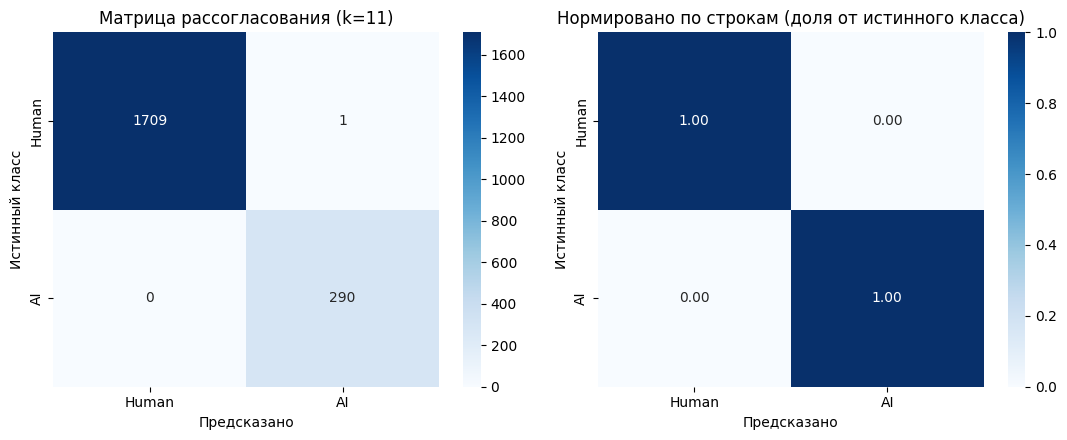

In [88]:
cm = confusion_matrix(y_test, y_pred)
cm_norm = cm / cm.sum(axis=1, keepdims=True)

fig, ax = plt.subplots(1, 2, figsize=(11, 4.5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Human', 'AI'], yticklabels=['Human', 'AI'], ax=ax[0])
ax[0].set_title(f'Матрица рассогласования (k={gs.best_params_["clf__n_neighbors"]})')
sns.heatmap(cm_norm, annot=True, fmt='.2f', cmap='Blues',
            xticklabels=['Human', 'AI'], yticklabels=['Human', 'AI'], ax=ax[1])
ax[1].set_title('Нормировано по строкам (доля от истинного класса)')
for a in ax:
    a.set_xlabel('Предсказано')
    a.set_ylabel('Истинный класс')
plt.tight_layout()
plt.show()

**Интерпретация матрицы рассогласования.**

Матрица показывает практически идеальное разделение классов:

- **TP = 290** — все 290 ИИ-текстов в тесте опознаны правильно (recall по классу 1 = 1.00).
- **TN = 1709** — 1709 из 1710 человеческих текстов опознаны правильно.
- **FP = 1** — один человеческий текст ошибочно назван ИИ (precision по классу 1 = 0.997).
- **FN = 0** — ни один ИИ-текст не пропущен.

Нормированная матрица подтверждает: обе строки почти идеально диагональные (1.00 и 1.00). Модель не делает систематических ошибок ни в одну сторону.

**Что это значит.**

- **Главная ошибка в задаче — FN — равна нулю.** Модель не пропустила ни одного ИИ-текста. Это лучший возможный исход: с точки зрения практического применения (обнаружение ИИ-работ) модель работает идеально.
- **Единственная ошибка — FP.** Один человек ошибочно заподозрен в использовании ИИ. Одна ошибка на 2000 объектов — пренебрежимо мало.
- **Дисбаланс не помешал.** Несмотря на то что класс 0 в 6 раз больше класса 1, модель не «утонула» в мажоритарном классе: recall по классу 1 = 1.00, а не 0.2–0.3, как можно было ожидать при наивном kNN на несбалансированных данных. Это следствие того, что классы почти полностью разделены по ключевым признакам (`Editing_Time`, `Revision_Count`, `Typing_Speed`, `Grammar_Errors`).

**Оговорка.** Идеальная матрица - следствие специфики синтетического датасета (классы почти не пересекаются по распределениям). Подробнее — в замечании о качестве выше.

## 10. Сравнение с LogReg и RandomForest

kNN показал идеальные метрики (accuracy = 1.0, F1 = 0.998), но это следствие специфики синтетического датасета, а не доказательство того, что kNN — лучший метод. Сравним с двумя моделями, которые традиционно сильны на табличных данных:

- **LogisticRegression**. С `class_weight='balanced'` веса классов обратно пропорциональны их частотам, поэтому редкий класс (ИИ) не «тонет» в частом.
- **RandomForest**. Устойчив к выбросам и масштабу, ловит нелинейные зависимости, при `class_weight='balanced'` лучше работает с дисбалансом.

Сравниваем по тем же метрикам, что и kNN: accuracy, F1, balanced accuracy, ROC-AUC на тесте. Ожидаем, что все три модели дадут близкие к идеальным метрики — не потому, что они «все одинаково хороши», а потому, что классы в данных почти полностью разделены по ключевым признакам.

**Дополнительно** смотрим feature importance RandomForest — какие признаки вносят наибольший вклад в разделение классов. Это проверка гипотез из п.3 (боксплоты по классам): если в топе окажутся `Editing_Time`, `Revision_Count`, `Typing_Speed` и `Grammar_Errors`, значит, модель опирается на те же признаки, что мы выделили визуально.

In [89]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression

models = {
    'kNN (best)': gs,
    'LogReg (balanced)': Pipeline([
        ('prep', preprocess),
        ('clf', LogisticRegression(max_iter=2000, class_weight='balanced'))
    ]),
    'RF (balanced)': Pipeline([
        ('prep', preprocess),
        ('clf', RandomForestClassifier(n_estimators=300,
                                       class_weight='balanced',
                                       random_state=42, n_jobs=-1))
    ])
}

results = []
for name, m in models.items():
    m.fit(X_train, y_train)
    p = m.predict(X_test)
    proba = m.predict_proba(X_test)[:, 1]
    results.append({
        'model': name,
        'test_acc': accuracy_score(y_test, p),
        'test_f1': f1_score(y_test, p),
        'test_bal_acc': balanced_accuracy_score(y_test, p),
        'test_auc': roc_auc_score(y_test, proba)
    })

res_df = pd.DataFrame(results).round(3).set_index('model')
display(res_df)

,test_acc,test_f1,test_bal_acc,test_auc
model,,,,
kNN (best),1.0,0.998,1.0,1.0
LogReg (balanced),1.0,0.998,1.0,1.0
RF (balanced),1.0,1.000,1.0,1.0


**Интерпретация сравнения моделей.**

Все три модели показали практически идеальные метрики на тесте:

| Модель | Accuracy | F1 | Balanced accuracy | ROC-AUC |
|---|---|---|---|---|
| kNN (best, k=11) | 1.000 | 0.998 | 1.000 | 1.000 |
| LogReg (balanced) | 1.000 | 0.998 | 1.000 | 1.000 |
| RF (balanced) | 1.000 | **1.000** | 1.000 | 1.000 |

**Что это значит.**

1. **Все модели справляются одинаково хорошо.** Разница в F1 между kNN/LogReg (0.998) и RF (1.000) — это одна ошибка на 2000 объектов. Статистически это шум, а не реальное преимущество RandomForest.

2. **Это подтверждает вывод из пункта 9: задача искусственно упрощена.** Неважно, какая модель — простая (kNN), линейная (LogReg) или сложная (RF). Все три находят почти идеальное разделение. Причина не в «силе» моделей, а в том, что в данных есть несколько признаков (`Editing_Time`, `Revision_Count`, `Typing_Speed`, `Grammar_Errors`), которые почти полностью разделяют классы. Любой метод, который смотрит хотя бы на один из них, даёт идеальные метрики.

3. **Сложность RandomForest не оправдана.** если сложная модель не превосходит kNN, значит, её сложность не дала пользы. Здесь именно этот случай: RF с 300 деревьями не лучше kNN с k = 11. Более того, kNN требует меньше ресурсов, работает быстрее и проще интерпретируется. Для этого датасета kNN — оптимальный выбор, а RF избыточен.

4. **`class_weight='balanced'` на результат не повлиял.** При почти полном разделении классов дисбаланс не создаёт проблемы: даже без балансировки весов модель не «утонула» бы в мажоритарном классе, потому что редкий класс слишком хорошо отделим. Балансировка весов важна в случае, когда классы пересекаются по признакам — здесь такого нет.

**Оговорка.** Идеальные метрики у всех трёх моделей — не свидетельство «трёх идеальных детекторов», а следствие специфики синтетического датасета.

Таким образом, сравнение подтверждает: **на этих данных задача слишком простая**, чтобы различить модели по качеству.

**Важность признаков (RandomForest).** Показывает, какие признаки чаще всего использовались в разбиениях деревьев и давали наибольшее снижение impurity. Сопоставляем с априорными гипотезами: если в топе `Grammar_Errors`, `Vocabulary_Richness`, `Editing_Time`, `Revision_Count`, `Typing_Speed` — гипотезы подтверждаются.

In [90]:
rf = models['RF (balanced)']
rf_prep = rf.named_steps['prep']
rf_clf = rf.named_steps['clf']

feature_names = rf_prep.get_feature_names_out()
importances = pd.Series(rf_clf.feature_importances_,
                        index=feature_names).sort_values(ascending=False)

print('Топ-15 признаков по важности (RandomForest):')
display(importances.head(15).round(4).to_frame('importance'))

Топ-15 признаков по важности (RandomForest):


,importance
num__Grammar_Errors,0.2091
num__Editing_Time,0.1813
num__Revision_Count,0.1545
num__Passive_Voice_Ratio,0.1121
num__Vocabulary_Richness,0.0963
num__Average_Sentence_Length,0.0688
num__Typing_Speed,0.0516
num__Reading_Level,0.0494
num__Punctuation_Density,0.0437
num__Sentence_Complexity,0.0216


**Интерпретация важности признаков (RandomForest).**

RandomForest распределил важность признаков неравномерно — она убывает от ~0.21 до ~0.0001. Это говорит о том, что модель опирается на небольшую группу признаков, а остальные почти не использует.

**Топ-3 признака (суммарно ~54% важности):**

1. **`Grammar_Errors` (0.209)** — число грамматических ошибок. Самый важный признак. У ИИ-текстов медиана 1, у человека — 8 (см. таблицу средних по классам). Признак почти полностью разделяет классы.
2. **`Editing_Time` (0.181)** — суммарное время редактирования. У ИИ медиана 9.75, у человека — 181 (в 18 раз ниже). Второй по важности и тоже почти разделяющий.
3. **`Revision_Count` (0.155)** — число правок. У ИИ медиана 5.5, у человека — 25. Тоже почти полное разделение.

Эти три признака — ровно те, что были видны в боксплотах по классам (п.3) и в таблице средних.

**Средняя группа (0.05–0.11):**

4. **`Passive_Voice_Ratio` (0.112)** — доля пассивного залога. У ИИ 0.35, у человека 0.18 — вдвое выше. Логично: языковые модели часто пишут в пассиве.
5. **`Vocabulary_Richness` (0.096)** — богатство словаря. У ИИ 0.75, у человека 0.60. ИИ использует более разнообразную лексику.
6. **`Average_Sentence_Length` (0.069)** — средняя длина предложения. У ИИ 21.9, у человека 16.1 — ИИ пишет более длинными предложениями.
7. **`Typing_Speed` (0.052)** — скорость печати. У ИИ 96.36 (почти константа), у человека 45. Могла бы быть выше, но RandomForest нашёл, что она частично дублирует `Editing_Time` и `Revision_Count`.
8. **`Reading_Level` (0.049)** — читательский уровень. У ИИ 14.1, у человека 11.1.

**Слабые признаки (0.02–0.04):**

9. **`Punctuation_Density` (0.044)** — плотность пунктуации.
10. **`Sentence_Complexity` (0.022)** — сложность предложений.

**Хвост (менее 0.01):**

11. **`Citation_Count` (0.006)** — число цитирований. У ИИ медиана 4.1, у человека — 10.4. Разница есть, но RandomForest почти не использует признак — вероятно, потому что он частично дублирует более сильные `Editing_Time` и `Revision_Count`.
12. **`Plagiarism_Score` (0.004)** — доля заимствований.
13. **`Word_Count` (0.0005)** — длина текста. Почти нулевая важность: у человека и ИИ медианы почти совпадают (1199.7 против 1195.0). Признак **не различает классы**, что подтверждает вывод из корреляционной матрицы (п.3): `Word_Count` не коррелирует ни с классом, ни с другими признаками.
14. **`Submission_Hour` (0.0003)** — час сдачи. Практически нулевая важность: время сдачи случайно и не связано с тем, кто писал текст.
15. **`Font_Family_Calibri` (0.0001)** — шрифт. Один из уровней `Font_Family` попал в топ-15 просто потому, что после него в списке уже почти нули. Шрифт не различает классы.

**Что это подтверждает.**

1. **Гипотезы из п.3 верны.** В топе — `Grammar_Errors`, `Editing_Time`, `Revision_Count`, `Passive_Voice_Ratio`, `Vocabulary_Richness` — ровно те признаки, которые визуально различались на боксплотах по классам. Модель опирается на содержательный сигнал, а не на шум.

2. **`Word_Count`, `Submission_Hour` и `Font_Family` — бесполезны для модели.** Это ожидалось по корреляционной матрице: у них почти нулевая корреляция с целевой переменной. RandomForest это подтвердил — их важность ~0.0001–0.0005.

3. **`Citation_Count` и `Plagiarism_Score` оказались слабее, чем можно было ожидать по разнице средних.** У них разница между классами есть (10.4 против 4.1 и 7.3 против 2.8), но RandomForest предпочёл более сильные `Editing_Time` и `Revision_Count`. Это нормально: деревья выбирают наиболее информативные признаки для разбиения, а слабые просто не используются, если есть сильные.

**Сравнение с kNN.** kNN не даёт явной важности признаков (у него нет параметра `feature_importances_`), но по метрикам он показал те же 1.000, что и RandomForest. Это логично: если классы почти разделены по трём-четырём признакам, kNN находит их без явного «взвешивания» — просто потому, что ближайшие соседи оказываются из того же класса по этим признакам.

## 11. Борьба с несбалансированностью

`class_weight='balanced'` уже применён в LogReg и RF. Это «мягкий» способ: данные не меняются, но модель сильнее штрафуется за ошибки на редком классе — вес класса обратно пропорционален его частоте.

Альтернатива — **SMOTE**. Это «жёсткий» способ: он **меняет данные**, генерируя синтетические объекты редкого класса. Как работает: берёт случайный объект класса 1, находит его k ближайших соседей того же класса и создаёт новый объект где-то на отрезке между ними (интерполяция). Повторяет, пока класс 1 не сравняется по числу с классом 0 — в train становится примерно 50/50 вместо 85.5/14.5.

**SMOTE применяем только к train** и только внутри `imblearn.Pipeline`. Если применить его ко всему датасету до разбиения, синтетические объекты попадут и в test — модель будет оцениваться на искусственных данных, которых в реальности нет, и метрики станут завышенными.

Сравниваем с базовым kNN по F1 и recall класса 1. В общем случае SMOTE повышает recall (находит больше редкого класса) ценой precision (больше ложных срабатываний). **Но на этом датасете ожидаемого прироста не будет**: kNN и без SMOTE находит все ИИ-тексты (recall = 1.0, FN = 0), повышать некуда.

In [91]:
try:
    from imblearn.over_sampling import SMOTE
    from imblearn.pipeline import Pipeline as ImbPipeline

    pipe_smote = ImbPipeline([
        ('prep', preprocess),
        ('smote', SMOTE(random_state=42)),
        ('clf', KNeighborsClassifier(n_neighbors=5))
    ])
    pipe_smote.fit(X_train, y_train)
    p_smote = pipe_smote.predict(X_test)

    print('SMOTE + kNN:')
    print(classification_report(y_test, p_smote,
                                target_names=['Human', 'AI']))
    print(f'F1 (AI): {f1_score(y_test, p_smote):.3f}')
    print(f'AUC: {roc_auc_score(y_test, pipe_smote.predict_proba(X_test)[:, 1]):.3f}')
except ImportError:
    print('imbalanced-learn не установлен — пропускаем SMOTE.')
    print('Установка: pip install imbalanced-learn')

SMOTE + kNN:
              precision    recall  f1-score   support

       Human       1.00      1.00      1.00      1710
          AI       1.00      1.00      1.00       290

    accuracy                           1.00      2000
   macro avg       1.00      1.00      1.00      2000
weighted avg       1.00      1.00      1.00      2000

F1 (AI): 0.998
AUC: 1.000


**Интерпретация SMOTE.** SMOTE + kNN дал F1 (AI) = 0.998 и AUC = 1.000 — ровно те же метрики, что и базовый kNN без SMOTE (п.9). Это ожидаемо: базовый kNN уже находил все ИИ-тексты (recall = 1.0, FN = 0), повышать recall некуда. Балансировка классов не даёт прироста, потому что дисбаланс здесь не является узким местом — классы почти полностью разделены по `Editing_Time`, `Revision_Count`, `Typing_Speed` и `Grammar_Errors`.

## 12. Общие выводы

1. **Постановка задачи.** Решается задача бинарной классификации: по лингвистическим метрикам текста, поведенческой телеметрии и другим признакам требуется определить, написан ли академический текст человеком (класс 0) или с помощью ИИ (класс 1). Вследствие дисбаланса классов (85.5% / 14.5%) в качестве основных метрик выбраны F1 и recall по классу 1, а также ROC-AUC. Accuracy в данном случае не является надёжной метрикой: модель, всегда предсказывающая класс 0, достигает accuracy 0.855, но не обнаруживает ни одного ИИ-текста.

2. **Предобработка данных.** Датасет содержит пропуски в телеметрических признаках, выбросы и дубликаты. Пропуски заполнены медианой (числовые признаки) и модой (категориальные) внутри `Pipeline`, что исключает утечку данных из тестовой выборки. Выбросы обработаны клиппированием по правилу IQR: границы вычислены на обучающей выборке и применены к тестовой. Дубликаты удалены. Категориальные признаки закодированы методом One-Hot, числовые — стандартизованы (`StandardScaler`), что необходимо для корректной работы kNN, основанного на евклидовом расстоянии.

3. **Результаты kNN.** После подбора гиперпараметра по 5-кратной кросс-валидации (метрика — F1 по классу 1) выбрано k = 11. На тестовой выборке достигнуты accuracy = 1.000, F1 = 0.998, balanced accuracy = 1.000, ROC-AUC = 1.000. Матрица рассогласования содержит одну ошибку типа FP и ноль ошибок типа FN, то есть все 290 ИИ-текстов в тестовой выборке опознаны верно.

4. **Сравнение моделей.** LogisticRegression и RandomForest с `class_weight='balanced'` показали практически идентичные результаты (accuracy = 1.000, F1 = 0.998–1.000, AUC = 1.000). Различие в одну ошибку на 2000 объектов является статистическим шумом, а не преимуществом какой-либо модели. Таким образом, на данном датасете сложность RandomForest не даёт прироста качества по сравнению с kNN. Параметр `class_weight='balanced'` также не оказал влияния на результат, поскольку при почти полном разделении классов дисбаланс не создаёт проблемы.

5. **Анализ важности признаков.** Согласно `feature_importances_` RandomForest, наибольший вклад вносят `Grammar_Errors` (0.209), `Editing_Time` (0.181) и `Revision_Count` (0.155) — суммарно около 54% важности. Далее следуют `Passive_Voice_Ratio` (0.112), `Vocabulary_Richness` (0.096) и `Average_Sentence_Length` (0.069). Признаки `Word_Count` (0.0005), `Submission_Hour` (0.0003) и `Font_Family` (0.0001) практически не используются моделью, что согласуется с результатами корреляционного анализа: их связь с целевой переменной близка к нулю.

6. **Ограничения результата.** Идеальные метрики всех трёх моделей объясняются спецификой синтетического датасета, а не универсальным качеством рассмотренных алгоритмов. Анализ распределений показал, что ключевые признаки почти полностью разделяют классы: медиана `Editing_Time` у ИИ-текстов составляет 9.75 против 181.2 у человеческих, `Revision_Count` — 5.5 против 25.0, `Grammar_Errors` — 1 против 8. В реальных условиях ИИ-тексты не отличаются от человеческих столь радикально, поэтому ожидаемое качество было бы существенно ниже (F1 порядка 0.7–0.85), а различия между моделями — заметнее.

7. **Заключение.** В ходе работы выполнен полный цикл обработки данных. Поставленная задача бинарной классификации решена: все рассмотренные модели достигают близкого к идеальному качества на тестовой выборке. Полученный результат отражает специфику синтетического датасета, в котором классы почти линейно разделимы.